In [4]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

In [5]:
load_dotenv()

True

In [6]:
model = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")

In [7]:
class JokeState(TypedDict):

    topic: str
    joke: str
    explanation: str

In [8]:
def generate_joke(state: JokeState):

    prompt = f'generate a joke on the topic {state["topic"]}'
    response = model.invoke(prompt).content

    return {'joke': response}


In [9]:
def generate_explanation(state: JokeState):

    prompt = f'write an explanation for the joke - {state["joke"]}'
    response = model.invoke(prompt).content

    return {'explanation': response}

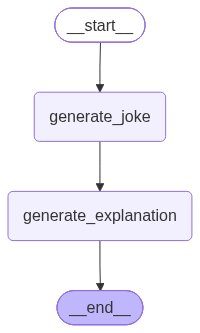

In [10]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explanation', generate_explanation)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explanation')
graph.add_edge('generate_explanation', END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)
workflow

In [11]:
config1 = {"configurable": {"thread_id": "1"}}
workflow.invoke({'topic':'pizza'}, config=config1)

{'topic': 'pizza',
 'joke': [{'type': 'text',
   'text': 'Why does a pizza maker never get lonely?\n\nBecause they’re always surrounded by **knead-y** people!',
   'extras': {'signature': 'EnMKcQFpFH0TnJs1I9LdmjH2LlexlKtdt+RljSCHGhDZTT8+V4Fwl7veavLiZetHmRrchfUDs+rREI9nA+1+HWCALp4pZznjxvp5s/+7BkX0tfYd7b4ski7ju6gUCwPv9MrwQTbaRa2rDK/KFJVjyhxuz8IF'}}],
 'explanation': [{'type': 'text',
   'text': 'This joke relies on a **pun**, which is a play on words that sound the same but have different meanings.\n\nHere is the breakdown:\n\n1.  **The Context:** The joke is about a "pizza maker." A crucial part of making pizza dough is the process of **kneading** it—pressing, folding, and stretching the dough with your hands to develop its texture.\n2.  **The Pun:** The word **"knead-y"** is a play on the word **"needy."** In English, being "needy" means you require a lot of attention or emotional support from others, often to the point of being clingy.\n3.  **The Connection:** \n    *   Because a pizz

In [12]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'pizza', 'joke': [{'type': 'text', 'text': 'Why does a pizza maker never get lonely?\n\nBecause they’re always surrounded by **knead-y** people!', 'extras': {'signature': 'EnMKcQFpFH0TnJs1I9LdmjH2LlexlKtdt+RljSCHGhDZTT8+V4Fwl7veavLiZetHmRrchfUDs+rREI9nA+1+HWCALp4pZznjxvp5s/+7BkX0tfYd7b4ski7ju6gUCwPv9MrwQTbaRa2rDK/KFJVjyhxuz8IF'}}], 'explanation': [{'type': 'text', 'text': 'This joke relies on a **pun**, which is a play on words that sound the same but have different meanings.\n\nHere is the breakdown:\n\n1.  **The Context:** The joke is about a "pizza maker." A crucial part of making pizza dough is the process of **kneading** it—pressing, folding, and stretching the dough with your hands to develop its texture.\n2.  **The Pun:** The word **"knead-y"** is a play on the word **"needy."** In English, being "needy" means you require a lot of attention or emotional support from others, often to the point of being clingy.\n3.  **The Connection:** \n    *   Beca

In [13]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': [{'type': 'text', 'text': 'Why does a pizza maker never get lonely?\n\nBecause they’re always surrounded by **knead-y** people!', 'extras': {'signature': 'EnMKcQFpFH0TnJs1I9LdmjH2LlexlKtdt+RljSCHGhDZTT8+V4Fwl7veavLiZetHmRrchfUDs+rREI9nA+1+HWCALp4pZznjxvp5s/+7BkX0tfYd7b4ski7ju6gUCwPv9MrwQTbaRa2rDK/KFJVjyhxuz8IF'}}], 'explanation': [{'type': 'text', 'text': 'This joke relies on a **pun**, which is a play on words that sound the same but have different meanings.\n\nHere is the breakdown:\n\n1.  **The Context:** The joke is about a "pizza maker." A crucial part of making pizza dough is the process of **kneading** it—pressing, folding, and stretching the dough with your hands to develop its texture.\n2.  **The Pun:** The word **"knead-y"** is a play on the word **"needy."** In English, being "needy" means you require a lot of attention or emotional support from others, often to the point of being clingy.\n3.  **The Connection:** \n    *   Bec

### Time Travel

In [15]:
workflow.get_state({'configurable': {'thread_id': '1', 'checkpoint_id':'1f1d6f45-f4c2-6fde-8000-a06bb44f31e2' }})

StateSnapshot(values={'topic': 'pizza'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_id': '1f1d6f45-f4c2-6fde-8000-a06bb44f31e2'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-11-02T19:34:08.438855+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6f45-f4bb-69b5-bfff-3be2c5f559f3'}}, tasks=(PregelTask(id='3777d1a4-82ea-1565-7472-223b3eb85b83', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result={'joke': [{'type': 'text', 'text': 'Why does a pizza maker never get lonely?\n\nBecause they’re always surrounded by **knead-y** people!', 'extras': {'signature': 'EnMKcQFpFH0TnJs1I9LdmjH2LlexlKtdt+RljSCHGhDZTT8+V4Fwl7veavLiZetHmRrchfUDs+rREI9nA+1+HWCALp4pZznjxvp5s/+7BkX0tfYd7b4ski7ju6gUCwPv9MrwQTbaRa2rDK/KFJVjyhxuz8IF'}}]}),), interrupts=())

In [17]:
workflow.invoke(None, {'configurable': {'thread_id': '1', 'checkpoint_id':'1f1d6f45-f4c2-6fde-8000-a06bb44f31e2' }})

{'topic': 'pizza',
 'joke': [{'type': 'text',
   'text': 'Why does pizza have the best sense of humor?\n\nBecause it’s always **cheesy**!',
   'extras': {'signature': 'EnMKcQFpFH0T1qteRam/ug00OsRidDzkZeims3hQdW81hjOoxmYp0Sp+dK33m61LQmAXLEJyA59YeZW+4ltBAJsI+2tTIOMod6E3HofTcqSgxgEKjd7BYhmSs5rtt1fO14xKtle+NKDereN3BpN1LCl7GFSA'}}],
 'explanation': [{'type': 'text',
   'text': 'This joke relies on a **pun**, which is a play on words that have similar sounds or multiple meanings.\n\nHere is the breakdown of why it is considered funny:\n\n1.  **The Double Meaning:** The word **"cheesy"** has two common definitions:\n    *   **Literal:** It describes something containing a lot of cheese (like pizza).\n    *   **Figurative:** It is a slang term used to describe something—like a joke—that is silly, overly sentimental, or intentionally corny.\n\n2.  **The Punchline:** By saying the pizza is "cheesy," the joke is simultaneously describing the pizza\'s physical ingredients and calling the joke itse

In [18]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': [{'type': 'text', 'text': 'Why does pizza have the best sense of humor?\n\nBecause it’s always **cheesy**!', 'extras': {'signature': 'EnMKcQFpFH0T1qteRam/ug00OsRidDzkZeims3hQdW81hjOoxmYp0Sp+dK33m61LQmAXLEJyA59YeZW+4ltBAJsI+2tTIOMod6E3HofTcqSgxgEKjd7BYhmSs5rtt1fO14xKtle+NKDereN3BpN1LCl7GFSA'}}], 'explanation': [{'type': 'text', 'text': 'This joke relies on a **pun**, which is a play on words that have similar sounds or multiple meanings.\n\nHere is the breakdown of why it is considered funny:\n\n1.  **The Double Meaning:** The word **"cheesy"** has two common definitions:\n    *   **Literal:** It describes something containing a lot of cheese (like pizza).\n    *   **Figurative:** It is a slang term used to describe something—like a joke—that is silly, overly sentimental, or intentionally corny.\n\n2.  **The Punchline:** By saying the pizza is "cheesy," the joke is simultaneously describing the pizza\'s physical ingredients and calling th

### Updating State

In [20]:
workflow.update_state({'configurable': 
                       {'thread_id': '1',
                        'checkpoint_id':'1f1d6f45-f4c2-6fde-8000-a06bb44f31e2',
                        'checkpoint_ns': ''  }},
                        {'topic': 'samosa'})

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1d6f6e-e5ef-6c5d-8001-7cbcaa30dd17'}}

In [21]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6f6e-e5ef-6c5d-8001-7cbcaa30dd17'}}, metadata={'source': 'update', 'step': 1, 'parents': {}}, created_at='2026-11-02T19:52:27.469714+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d6f45-f4c2-6fde-8000-a06bb44f31e2'}}, tasks=(PregelTask(id='ae41189b-e54d-bb6d-98fd-c38909238539', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'pizza', 'joke': [{'type': 'text', 'text': 'Why does pizza have the best sense of humor?\n\nBecause it’s always **cheesy**!', 'extras': {'signature': 'EnMKcQFpFH0T1qteRam/ug00OsRidDzkZeims3hQdW81hjOoxmYp0Sp+dK33m61LQmAXLEJyA59YeZW+4ltBAJsI+2tTIOMod6E3HofTcqSgxgEKjd7BYhmSs5rtt1fO14xKtle+NKDereN3BpN1LCl7GFSA'}}], 'explanation': [{'type': 'text', 't

In [22]:
workflow.invoke(None, {"configurable": {"thread_id": "1", "checkpoint_id": "1f1d6f6e-e5ef-6c5d-8001-7cbcaa30dd17"}})

{'topic': 'samosa',
 'joke': [{'type': 'text',
   'text': 'Why did the samosa go to the doctor?\n\nBecause it was feeling a little **stuffed**, and it was starting to lose its **filling**!',
   'extras': {'signature': 'EnMKcQFpFH0TjD16BoYyRS0E1ugDBRr8wwCOTMGIM1f9ELgtfT5Ffq4Kd8okIvpmilVzBx92JAM70UGoFxdI+y7awVlO9ewop5FONh+g7j9c72wSDhTw4QKipVSwhirfip/9tbw8PMxCKGRW1IKEnbrCMcCc'}}],
 'explanation': [{'type': 'text',
   'text': 'This joke relies on a **pun**, which is a play on words that have similar sounds or multiple meanings. Here is the breakdown:\n\n1.  **"Stuffed":** In the context of food (like a samosa), "stuffed" refers to the savory mixture of potatoes, peas, or meat inside the pastry. However, in human terms, "feeling stuffed" describes the uncomfortable physical sensation of having eaten too much food.\n2.  **"Filling":** This is the punchline that connects the food item to the medical situation.\n    *   **In food:** The "filling" is the actual ingredient inside the samosa.\n  

In [23]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa', 'joke': [{'type': 'text', 'text': 'Why did the samosa go to the doctor?\n\nBecause it was feeling a little **stuffed**, and it was starting to lose its **filling**!', 'extras': {'signature': 'EnMKcQFpFH0TjD16BoYyRS0E1ugDBRr8wwCOTMGIM1f9ELgtfT5Ffq4Kd8okIvpmilVzBx92JAM70UGoFxdI+y7awVlO9ewop5FONh+g7j9c72wSDhTw4QKipVSwhirfip/9tbw8PMxCKGRW1IKEnbrCMcCc'}}], 'explanation': [{'type': 'text', 'text': 'This joke relies on a **pun**, which is a play on words that have similar sounds or multiple meanings. Here is the breakdown:\n\n1.  **"Stuffed":** In the context of food (like a samosa), "stuffed" refers to the savory mixture of potatoes, peas, or meat inside the pastry. However, in human terms, "feeling stuffed" describes the uncomfortable physical sensation of having eaten too much food.\n2.  **"Filling":** This is the punchline that connects the food item to the medical situation.\n    *   **In food:** The "filling" is the actual ingredient inside the 